[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lgonperez3-glitch/MLSM-labs/blob/main/Lab3/lab3_autoencoder_mtat_v2.ipynb)

# Lab 3 — Autoencoder convolucional para MagnaTagATune

**Machine Learning for Sound and Music — UPF**

En este notebook construiremos y entrenaremos dos autoencoders para reconstruir audio del conjunto **MagnaTagATune (MTAT)**.

Un *autoencoder* es una red neuronal que aprende a comprimir una señal en una representación pequeña y después intenta reconstruir la señal original.

## Qué haremos

1. Descargar y preparar los audios de MTAT.
2. Convertir cada audio a mono y 16 kHz.
3. Utilizar segmentos de **1 segundo** (16 000 muestras).
4. Entrenar un modelo baseline y otro mejorado.
5. Comparar ambos mediante el **MSE de validación**.
6. Escuchar y visualizar algunas reconstrucciones.

El notebook está pensado para ejecutarse de principio a fin en **Google Colab con GPU**. La primera descarga del dataset ocupa aproximadamente 2,8 GB y puede tardar.

> Ejecuta las celdas en orden. Los resultados y las gráficas se generarán al terminar los entrenamientos y se guardarán en `MyDrive/MLSM/Lab 3/results_v2`; no se incluyen resultados inventados.

## 1. Diseño del experimento

### ¿Por qué usamos segmentos de un segundo?

Los audios de MTAT son más largos que los ejemplos de un segundo utilizados en la práctica de clase. Para que todos los ejemplos tengan la misma longitud, extraemos un segmento de un segundo de cada canción.

- Frecuencia de muestreo: **16 000 Hz**.
- Canales: **mono**.
- Longitud de cada segmento: **16 000 muestras**.
- Entrenamiento: utilizamos un segmento aleatorio fijo por canción, preparado una sola vez.
- Validación: utilizamos siempre el segmento central del audio.

### ¿Qué es el bottleneck?

El *bottleneck* es la representación comprimida que conecta el encoder con el decoder. En los dos modelos tendrá **512 valores**.

La tasa de compresión nominal será:

\[
\frac{16\,000}{512} = 31.25
\]

Por tanto, ambos modelos tendrán la misma longitud de entrada y el mismo tamaño de bottleneck. No cambiaremos esta compresión al mejorar la arquitectura.

### ¿Qué modelos comparamos?

| Modelo | Arquitectura | Función de pérdida |
|---|---|---|
| Baseline | 3 bloques convolucionales | MSE |
| Mejorado | Más convoluciones, mismas reducciones de tamaño | MSE + pérdida espectral |

El **MSE** mide la diferencia entre las muestras de audio original y reconstruido. La pérdida espectral compara también sus representaciones en frecuencia.

Aunque el segundo modelo se entrena con dos términos de pérdida, elegiremos y compararemos los modelos usando exclusivamente el **MSE de validación**.

## 2. Instalación de dependencias

Este notebook utiliza PyTorch para construir y entrenar las redes, y librosa para leer los archivos MP3 y convertirlos a 16 kHz.

Google Colab suele incluir PyTorch y una versión compatible con su GPU. Por eso no reinstalamos PyTorch: así evitamos cambiar accidentalmente la versión de CUDA del entorno.

In [1]:
# FFmpeg permite decodificar archivos MP3.
!apt-get -qq update
!apt-get -qq install -y ffmpeg

# Librerías auxiliares para audio, datos, gráficas y barras de progreso.
!pip -q install librosa==0.10.2.post1 scikit-learn matplotlib pandas tqdm

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 3. Importaciones y configuración

En esta sección definimos los parámetros del experimento en un único lugar. Si más adelante quieres cambiar, por ejemplo, el número de épocas, puedes hacerlo aquí.

También fijamos las semillas aleatorias. Una semilla permite repetir las mismas decisiones aleatorias, como el orden de los ejemplos o la inicialización de los pesos.

Usaremos `num_workers=0`: los datos se cargarán en el proceso principal. Esto evita los avisos de destrucción de procesos hijos que aparecían con el DataLoader multiproceso en Colab.

In [2]:
import os
import random
import shutil
import subprocess
from pathlib import Path
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from IPython.display import Audio, display

# ---------------------------------------------------------
# 1) Semillas y reproducibilidad
# ---------------------------------------------------------

SEED = 42

def set_seed(seed=SEED):
    """Fija las semillas de Python, NumPy y PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Favorece resultados reproducibles en las operaciones de cuDNN.
    # Puede hacer que algunas operaciones sean algo más lentas.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# ---------------------------------------------------------
# 2) Dispositivo: GPU si está disponible; CPU en caso contrario
# ---------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ---------------------------------------------------------
# 3) Parámetros del audio y del experimento
# ---------------------------------------------------------

SAMPLE_RATE = 16_000
SEGMENT_SECONDS = 1
INPUT_LENGTH = SAMPLE_RATE * SEGMENT_SECONDS

BOTTLENECK_SIZE = 512
COMPRESSION_RATE = INPUT_LENGTH / BOTTLENECK_SIZE

BATCH_SIZE = 32
NUM_EPOCHS = 8
LEARNING_RATE = 1e-3
PATIENCE = 3

# Importante: 0 evita crear procesos adicionales para cargar los audios.
NUM_WORKERS = 0

print(f"Frecuencia de muestreo: {SAMPLE_RATE} Hz")
print(f"Longitud de entrada: {INPUT_LENGTH} muestras ({SEGMENT_SECONDS} segundo)")
print(f"Bottleneck: {BOTTLENECK_SIZE} valores")
print(f"Compresión nominal: {COMPRESSION_RATE:.2f} a 1")

Dispositivo: cuda
GPU: Tesla T4
Frecuencia de muestreo: 16000 Hz
Longitud de entrada: 16000 muestras (1 segundo)
Bottleneck: 512 valores
Compresión nominal: 31.25 a 1


## 4. Google Drive, descarga y extracción de MagnaTagATune

Montamos Google Drive y guardamos los datos en `MyDrive/MLSM/Lab 3/data` y los resultados de esta versión en `MyDrive/MLSM/Lab 3/results_v2`.

Descargamos las tres partes del dataset solo cuando sea necesario. Si ya están descargadas, `wget -c` no vuelve a transferir los datos completos; si una descarga quedó interrumpida, puede continuarla.

El ZIP combinado, los audios extraídos y los segmentos preparados también se reutilizan en ejecuciones posteriores. Los resultados de los experimentos se guardan por separado en `results_v2`, sin sobrescribir los resultados de la primera versión.

La primera ejecución requiere autorizar el acceso de Colab a Google Drive.

In [3]:
# Conectamos Google Drive para que los datos se conserven entre sesiones de Colab.
from google.colab import drive
drive.mount("/content/drive")

# Todos los archivos del dataset se guardarán en esta carpeta de Mi unidad.
# Path gestiona correctamente los espacios de "Lab 3".
DATA_ROOT = Path("/content/drive/MyDrive/MLSM/Lab 3/data")

# Los resultados de esta versión se guardan separados de los originales.
RESULTS_DIR = Path("/content/drive/MyDrive/MLSM/Lab 3/results_v2")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Carpeta de resultados:", RESULTS_DIR)
DOWNLOAD_DIR = DATA_ROOT / "downloads"
AUDIO_DIR = DATA_ROOT / "audio"

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_DIR.mkdir(parents=True, exist_ok=True)

print("Carpeta de datos:", DATA_ROOT)

PARTS = ["mp3.zip.001", "mp3.zip.002", "mp3.zip.003"]
BASE_URL = "https://mirg.city.ac.uk/datasets/magnatagatune"

# wget -c continúa una descarga incompleta. Si el archivo ya está completo,
# no vuelve a descargar su contenido.
for part in PARTS:
    destination = DOWNLOAD_DIR / part

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Archivo ya presente (se comprobará si está completo): {part}")
    else:
        print(f"Descargando {part}...")

    subprocess.run(
        ["wget", "-c", f"{BASE_URL}/{part}", "-P", str(DOWNLOAD_DIR)],
        check=True
    )

    print(f"Tamaño local: {destination.stat().st_size / (1024 ** 3):.2f} GB")

Mounted at /content/drive
Carpeta de resultados: /content/drive/MyDrive/MLSM/Lab 3/results_v2
Carpeta de datos: /content/drive/MyDrive/MLSM/Lab 3/data
Descargando mp3.zip.001...
Tamaño local: 1.02 GB
Descargando mp3.zip.002...
Tamaño local: 1.02 GB
Descargando mp3.zip.003...
Tamaño local: 0.72 GB


In [4]:
# Unimos las partes solo si el ZIP no existe o su tamaño no coincide con ellas.
MERGED_ARCHIVE = DOWNLOAD_DIR / "mp3.zip"
expected_archive_size = sum((DOWNLOAD_DIR / part).stat().st_size for part in PARTS)

if not MERGED_ARCHIVE.exists() or MERGED_ARCHIVE.stat().st_size != expected_archive_size:
    print("Creando el archivo ZIP combinado...")
    temporary_archive = DOWNLOAD_DIR / "mp3.zip.tmp"

    with open(temporary_archive, "wb") as output_file:
        for part in PARTS:
            with open(DOWNLOAD_DIR / part, "rb") as input_file:
                shutil.copyfileobj(input_file, output_file)

    # Comprobamos el ZIP antes de sustituir el archivo definitivo.
    print("Comprobando que el archivo ZIP no está dañado...")
    subprocess.run(["unzip", "-tq", str(temporary_archive)], check=True)
    temporary_archive.replace(MERGED_ARCHIVE)
else:
    print("El ZIP combinado ya existe. Se reutiliza sin volver a crearlo.")

# La marca se crea únicamente cuando unzip termina correctamente.
EXTRACTION_MARKER = AUDIO_DIR / ".extraction_complete"
existing_mp3_count = sum(1 for _ in AUDIO_DIR.rglob("*.mp3"))
extraction_is_complete = False

if EXTRACTION_MARKER.exists():
    try:
        previous_mp3_count = int(EXTRACTION_MARKER.read_text().strip())
        extraction_is_complete = existing_mp3_count == previous_mp3_count and existing_mp3_count > 0
    except (ValueError, OSError):
        extraction_is_complete = False

if extraction_is_complete:
    print(f"La extracción ya está completa ({existing_mp3_count:,} MP3). Se reutilizan los archivos.")
else:
    print("Extrayendo los audios (solo será necesario la primera vez)...")
    subprocess.run(
        ["unzip", "-q", "-o", str(MERGED_ARCHIVE), "-d", str(AUDIO_DIR)],
        check=True
    )

    extracted_mp3_count = sum(1 for _ in AUDIO_DIR.rglob("*.mp3"))
    if extracted_mp3_count == 0:
        raise RuntimeError("La extracción terminó, pero no se encontraron archivos MP3.")

    EXTRACTION_MARKER.write_text(str(extracted_mp3_count))
    print(f"Extracción terminada: {extracted_mp3_count:,} archivos MP3.")

print("Carpeta de audios:", AUDIO_DIR)

Creando el archivo ZIP combinado...
Comprobando que el archivo ZIP no está dañado...
Extrayendo los audios (solo será necesario la primera vez)...
Extracción terminada: 25,863 archivos MP3.
Carpeta de audios: /content/drive/MyDrive/MLSM/Lab 3/data/audio


## 5. Localización y comprobación de los audios

Buscamos todos los archivos MP3 extraídos. Comprobamos que cada archivo se puede leer y que contiene al menos un segundo de audio.

Esta comprobación puede tardar porque el dataset contiene muchos archivos. La hacemos antes de entrenar para evitar que un archivo dañado interrumpa el entrenamiento a mitad de una época.

In [5]:
all_audio_paths = sorted(AUDIO_DIR.rglob("*.mp3"))

if not all_audio_paths:
    raise RuntimeError(
        "No se han encontrado archivos MP3. Comprueba la descarga y la extracción."
    )

valid_audio_paths = []

for path in tqdm(all_audio_paths, desc="Comprobando archivos MP3"):
    try:
        duration = librosa.get_duration(path=str(path))
        if duration >= SEGMENT_SECONDS:
            valid_audio_paths.append(path)
    except Exception:
        # Si un archivo está dañado o no se puede decodificar, lo omitimos.
        continue

if not valid_audio_paths:
    raise RuntimeError("No se ha encontrado ningún audio válido de al menos un segundo.")

print(f"Archivos encontrados: {len(all_audio_paths):,}")
print(f"Archivos válidos: {len(valid_audio_paths):,}")
print(f"Archivos omitidos: {len(all_audio_paths) - len(valid_audio_paths):,}")

Comprobando archivos MP3:   0%|          | 0/25863 [00:00<?, ?it/s]

/tmp/ipykernel_325/4183204262.py:12: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  duration = librosa.get_duration(path=str(path))
/tmp/ipykernel_325/4183204262.py:12: FutureWarning: PySoundFile failed. Trying audioread instead.
	Audioread support is deprecated in librosa 0.10.0 and will be removed in version 1.0.
  duration = librosa.get_duration(path=str(path))


Archivos encontrados: 25,863
Archivos válidos: 25,860
Archivos omitidos: 3


## 6. Separación en entrenamiento y validación

Separamos los archivos **antes** de extraer segmentos. Así, una misma canción no puede aparecer en los dos conjuntos.

- Entrenamiento (80 %): el modelo utiliza estos audios para aprender.
- Validación (20 %): medimos cómo reconstruye audios que no ha utilizado para ajustar sus pesos.

La semilla fija hace que la separación sea la misma cuando se vuelve a ejecutar el notebook con el mismo conjunto de archivos.

In [6]:
train_paths, val_paths = train_test_split(
    valid_audio_paths,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

print(f"Audios de entrenamiento: {len(train_paths):,}")
print(f"Audios de validación: {len(val_paths):,}")
print(f"Porcentaje de validación: {len(val_paths) / len(valid_audio_paths):.1%}")

Audios de entrenamiento: 20,688
Audios de validación: 5,172
Porcentaje de validación: 20.0%


## 7. Dataset: cómo convertimos un MP3 en un ejemplo de entrenamiento

Un `Dataset` es el objeto que sabe cómo obtener un ejemplo cada vez que el modelo lo necesita.

En la siguiente sección convertimos cada MP3 a mono y a 16 000 Hz, extraemos un segmento de un segundo y lo guardamos en disco. Así, durante el entrenamiento el modelo lee directamente los segmentos preparados, sin volver a decodificar los MP3.

El recorte de entrenamiento es aleatorio, pero reproducible: depende de la semilla y del índice del archivo. La validación utiliza siempre el segmento central. Los dos modelos reciben exactamente los mismos segmentos.

## 7. Preparación de segmentos de audio (una sola vez)

Decodificar miles de MP3 en cada época sería lento. Para que el notebook sea práctico en Colab, vamos a preparar **un segmento por canción** y guardarlo como una matriz de audio en disco.

- En entrenamiento elegimos un recorte aleatorio, pero reproducible, de cada canción.
- En validación elegimos el recorte central.
- Los dos modelos reutilizarán exactamente los mismos segmentos.
- Guardamos los datos como matrices `float32` para no tener que volver a decodificar los MP3 durante el entrenamiento.

El conjunto preparado ocupa aproximadamente 1,6 GB. Se guarda en `MyDrive/MLSM/Lab 3/data/prepared` y permanece en Drive entre sesiones. Si vuelves a ejecutar el notebook, las matrices existentes se reutilizan cuando tienen el tamaño esperado.

In [7]:
# Guardamos los segmentos preparados en Google Drive.
CACHE_DIR = DATA_ROOT / "prepared"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CACHE = CACHE_DIR / "train_audio.npy"
VAL_CACHE = CACHE_DIR / "val_audio.npy"

def prepare_audio_matrix(audio_paths, output_path, training, seed=SEED):
    """Decodifica cada MP3 una vez y guarda un segmento de un segundo."""
    output_path = Path(output_path)

    # Si el archivo preparado ya existe y tiene el tamaño esperado, lo reutilizamos.
    expected_bytes = len(audio_paths) * INPUT_LENGTH * np.dtype(np.float32).itemsize
    if output_path.exists() and output_path.stat().st_size == expected_bytes:
        print(f"Se reutiliza el archivo preparado: {output_path}")
        return

    # Creamos una matriz en disco. Así no necesitamos cargar todo el dataset en RAM.
    audio_matrix = np.lib.format.open_memmap(
        output_path,
        mode="w+",
        dtype=np.float32,
        shape=(len(audio_paths), INPUT_LENGTH)
    )

    for index, path in enumerate(tqdm(audio_paths, desc=f"Preparando {output_path.name}")):
        # Convertimos el MP3 a mono y a 16 kHz.
        audio, _ = librosa.load(path, sr=SAMPLE_RATE, mono=True)

        # Aseguramos que exista al menos un segundo.
        if len(audio) < INPUT_LENGTH:
            audio = np.pad(audio, (0, INPUT_LENGTH - len(audio)))

        max_start = len(audio) - INPUT_LENGTH

        if training:
            # El recorte aleatorio depende de la semilla y del índice del archivo.
            # Por tanto, se puede repetir exactamente.
            rng = random.Random(seed + index)
            start = rng.randint(0, max_start) if max_start > 0 else 0
        else:
            # En validación usamos siempre el centro del audio.
            start = max_start // 2

        segment = audio[start:start + INPUT_LENGTH].astype(np.float32)

        # Normalizamos cada segmento para que su amplitud máxima sea 0.95.
        peak = np.max(np.abs(segment))
        if peak > 1e-8:
            segment = 0.95 * segment / peak

        audio_matrix[index] = segment

    # Nos aseguramos de escribir todos los datos en el archivo.
    audio_matrix.flush()
    del audio_matrix
    print(f"Guardado: {output_path} ({output_path.stat().st_size / (1024 ** 3):.2f} GB)")


prepare_audio_matrix(train_paths, TRAIN_CACHE, training=True)
prepare_audio_matrix(val_paths, VAL_CACHE, training=False)

Preparando train_audio.npy:   0%|          | 0/20688 [00:00<?, ?it/s]

Guardado: /content/drive/MyDrive/MLSM/Lab 3/data/prepared/train_audio.npy (1.23 GB)


Preparando val_audio.npy:   0%|          | 0/5172 [00:00<?, ?it/s]

Guardado: /content/drive/MyDrive/MLSM/Lab 3/data/prepared/val_audio.npy (0.31 GB)


In [8]:
# Dataset sencillo: lee cada segmento directamente desde las matrices guardadas en Drive.
class PreparedAudioDataset(Dataset):
    def __init__(self, audio_file):
        self.audio_file = Path(audio_file)
        self.audio_matrix = np.load(self.audio_file, mmap_mode="r")

    def __len__(self):
        return self.audio_matrix.shape[0]

    def __getitem__(self, index):
        # Copiamos solo el segmento solicitado, no toda la matriz.
        audio = np.array(self.audio_matrix[index], dtype=np.float32, copy=True)
        return torch.from_numpy(audio)


train_dataset = PreparedAudioDataset(TRAIN_CACHE)
val_dataset = PreparedAudioDataset(VAL_CACHE)

print(f"Ejemplos de entrenamiento: {len(train_dataset):,}")
print(f"Ejemplos de validación: {len(val_dataset):,}")

Ejemplos de entrenamiento: 20,688
Ejemplos de validación: 5,172


In [9]:
def make_train_loader(seed=SEED):
    # El generador controla el orden aleatorio de los ejemplos.
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )


# La validación no se mezcla: siempre se recorre en el mismo orden.
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Comprobamos la forma de un lote.
train_loader_check = make_train_loader(SEED)
audio_batch = next(iter(train_loader_check))
print("Forma del lote:", audio_batch.shape)
print("Interpretación: (número de audios, número de muestras)")

Forma del lote: torch.Size([32, 16000])
Interpretación: (número de audios, número de muestras)


## 8. DataLoaders: cómo agrupamos los ejemplos

El `DataLoader` agrupa los ejemplos en lotes (*batches*) para que la red procese varios audios a la vez.

Usamos un generador aleatorio con la misma semilla para que el orden de los ejemplos sea reproducible. Crearemos un DataLoader nuevo para cada modelo: así ambos empezarán con la misma secuencia de lotes.

Usamos `num_workers=0` para evitar avisos relacionados con procesos secundarios. Como los audios ya están preparados, el entrenamiento no necesita decodificar MP3 en cada época.

In [10]:
def make_train_loader(seed=SEED):
    # Este generador controla el orden aleatorio de los ejemplos.
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )


# La validación no se mezcla: siempre se recorre en el mismo orden.
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Comprobamos la forma de un lote.
train_loader_check = make_train_loader(SEED)
audio_batch = next(iter(train_loader_check))
print("Forma del lote:", audio_batch.shape)
print("Interpretación: (número de audios, número de muestras)")

Forma del lote: torch.Size([32, 16000])
Interpretación: (número de audios, número de muestras)


## 9. Arquitectura del autoencoder

Un autoencoder tiene dos partes:

- **Encoder:** reduce la señal hasta obtener un vector pequeño (bottleneck).
- **Decoder:** utiliza ese vector para reconstruir la señal original.

En nuestro caso:

1. La entrada tiene 16 000 muestras.
2. Tres operaciones de *pooling* reducen la longitud temporal: 16 000 → 8 000 → 4 000 → 2 000.
3. La representación resultante tiene 32 canales y 2 000 posiciones: 64 000 valores.
4. Una capa totalmente conectada comprime esos valores a 512.
5. El decoder hace el proceso inverso y reconstruye 16 000 muestras.

Los dos modelos conservan exactamente estas dimensiones. El modelo mejorado añade convoluciones, pero no añade reducciones de tamaño ni modifica el bottleneck.

In [11]:
class AudioAutoencoder(nn.Module):
    def __init__(self, improved=False):
        super().__init__()

        self.improved = improved

        # ENCODER
        # Cada bloque aumenta el número de canales y reduce a la mitad
        # la longitud temporal mediante MaxPool1d.
        self.encoder_block1 = self.make_encoder_block(1, 8)
        self.encoder_block2 = self.make_encoder_block(8, 16)
        self.encoder_block3 = self.make_encoder_block(16, 32)

        # Después de tres pooling, la longitud es 16 000 / 8 = 2 000.
        self.encoded_length = INPUT_LENGTH // 8
        self.flattened_size = 32 * self.encoded_length

        # Esta capa crea el bottleneck de 512 valores.
        self.to_bottleneck = nn.Linear(self.flattened_size, BOTTLENECK_SIZE)

        # Esta capa expande el bottleneck a la forma anterior al encoder.
        self.from_bottleneck = nn.Linear(BOTTLENECK_SIZE, self.flattened_size)

        # DECODER
        # Cada ConvTranspose1d duplica la longitud temporal.
        self.decoder_up1 = nn.ConvTranspose1d(32, 16, kernel_size=4, stride=2, padding=1)
        self.decoder_up2 = nn.ConvTranspose1d(16, 8, kernel_size=4, stride=2, padding=1)
        self.decoder_up3 = nn.ConvTranspose1d(8, 1, kernel_size=4, stride=2, padding=1)

        # El modelo mejorado añade una convolución después de cada subida.
        if self.improved:
            self.decoder_extra1 = nn.Conv1d(16, 16, kernel_size=7, padding=3)
            self.decoder_extra2 = nn.Conv1d(8, 8, kernel_size=7, padding=3)

    def make_encoder_block(self, in_channels, out_channels):
        layers = [
            nn.Conv1d(in_channels, out_channels, kernel_size=7, padding=3),
            nn.GELU()
        ]

        # En el modelo mejorado añadimos una segunda convolución por bloque.
        if self.improved:
            layers += [
                nn.Conv1d(out_channels, out_channels, kernel_size=7, padding=3),
                nn.GELU()
            ]

        layers.append(nn.MaxPool1d(kernel_size=2))
        return nn.Sequential(*layers)

    def forward(self, x):
        # x tiene forma (batch, 16000).
        # Conv1d espera (batch, canales, longitud), por eso añadimos un canal.
        x = x.unsqueeze(1)

        # Encoder: 16000 -> 8000 -> 4000 -> 2000.
        x = self.encoder_block1(x)
        x = self.encoder_block2(x)
        x = self.encoder_block3(x)

        # Convertimos la representación en un vector.
        x = x.flatten(start_dim=1)

        # Compresión: 64000 -> 512.
        x = self.to_bottleneck(x)

        # Expansión: 512 -> 64000 -> (32 canales, 2000 posiciones).
        x = self.from_bottleneck(x)
        x = x.view(-1, 32, self.encoded_length)

        # Decoder: 2000 -> 4000 -> 8000 -> 16000.
        x = torch.nn.functional.gelu(self.decoder_up1(x))
        if self.improved:
            x = torch.nn.functional.gelu(self.decoder_extra1(x))

        x = torch.nn.functional.gelu(self.decoder_up2(x))
        if self.improved:
            x = torch.nn.functional.gelu(self.decoder_extra2(x))

        # La última capa devuelve un único canal de audio.
        x = self.decoder_up3(x)

        # Forma final: (batch, 16000).
        return x.squeeze(1)


# Comprobamos que los dos modelos conservan la misma forma de entrada y salida.
baseline_check = AudioAutoencoder(improved=False).to(DEVICE)
improved_check = AudioAutoencoder(improved=True).to(DEVICE)

with torch.no_grad():
    test_input = torch.zeros(2, INPUT_LENGTH, device=DEVICE)
    print("Salida baseline:", baseline_check(test_input).shape)
    print("Salida mejorada:", improved_check(test_input).shape)

del baseline_check, improved_check, test_input

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Salida baseline: torch.Size([2, 16000])
Salida mejorada: torch.Size([2, 16000])


## 10. Funciones de pérdida

### MSE (Mean Squared Error)

El MSE calcula el promedio del error cuadrático entre el audio original y el reconstruido. Cuanto menor sea, más parecidas son las muestras.

### Pérdida espectral multiescala

El audio también se puede representar mediante su espectro, que muestra cómo se distribuye la energía entre las frecuencias.

Calcularemos la diferencia entre los espectros de la señal original y la reconstruida usando tres tamaños de ventana. Esto permite observar diferencias a distintas resoluciones temporales y frecuenciales.

El modelo baseline se entrena solo con MSE. El mejorado utiliza:

\[
\text{Loss} = \text{MSE} + 0.05 \times \text{Spectral Loss}
\]

La validación y la selección del mejor modelo seguirán basándose en MSE, para que la comparación sea la misma en ambos casos.

In [12]:
mse_loss = nn.MSELoss()

def multi_scale_stft_loss(original, reconstructed):
    """Compara los espectros de dos lotes de audio a varias resoluciones."""
    total_loss = 0.0

    # Ventanas cortas, medias y largas.
    for n_fft in [256, 512, 1024]:
        hop_length = n_fft // 4

        window = torch.hann_window(n_fft, device=original.device)

        original_stft = torch.stft(
            original,
            n_fft=n_fft,
            hop_length=hop_length,
            window=window,
            return_complex=True
        )

        reconstructed_stft = torch.stft(
            reconstructed,
            n_fft=n_fft,
            hop_length=hop_length,
            window=window,
            return_complex=True
        )

        # Magnitud del espectro; log1p estabiliza valores pequeños y grandes.
        original_magnitude = torch.log1p(torch.abs(original_stft))
        reconstructed_magnitude = torch.log1p(torch.abs(reconstructed_stft))

        total_loss += torch.mean(torch.abs(original_magnitude - reconstructed_magnitude))

    return total_loss / 3


def calculate_training_loss(original, reconstructed, improved=False):
    """Devuelve la pérdida utilizada para actualizar los pesos del modelo."""
    mse = mse_loss(reconstructed, original)

    if improved:
        spectral = multi_scale_stft_loss(original, reconstructed)
        return mse + 0.05 * spectral

    return mse

## 11. Funciones de entrenamiento y evaluación

En cada época:

1. El modelo recibe un lote de audios.
2. Produce una reconstrucción.
3. Calculamos la pérdida.
4. PyTorch calcula los gradientes y actualiza los pesos.
5. Al terminar la época, medimos el MSE en validación.

**¿Qué es una época?** Una época es una pasada completa por todos los ejemplos de entrenamiento.

Guardaremos los pesos del modelo que consiga el menor MSE de validación. También aplicaremos *early stopping*: si la validación no mejora durante varias épocas, detenemos el entrenamiento para no seguir entrenando sin beneficio observado.

El MSE de validación se calcula igual para ambos modelos, independientemente de la pérdida utilizada para entrenarlos.

In [13]:
def evaluate_model(model, loader):
    """Calcula el MSE medio en validación, sin actualizar los pesos."""
    model.eval()
    total_squared_error = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in tqdm(loader, desc="Validación", leave=False):
            batch = batch.to(DEVICE, non_blocking=True)

            reconstructed = model(batch)
            batch_mse = torch.sum((reconstructed - batch) ** 2)

            total_squared_error += batch_mse.item()
            total_samples += batch.numel()

    return total_squared_error / total_samples


def train_model(model, train_loader, val_loader, improved=False, model_name="Model"):
    """Entrena un modelo y devuelve su historial y sus mejores pesos."""
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {
        "train_loss": [],
        "val_mse": []
    }

    best_val_mse = float("inf")
    best_epoch = 0
    best_state = None
    checkpoint_path = RESULTS_DIR / (model_name.lower() + "_best_v2.pt")
    epochs_without_improvement = 0

    for epoch in range(NUM_EPOCHS):
        # Los segmentos ya están preparados y son los mismos en todas las épocas.

        model.train()
        total_train_loss = 0.0
        number_of_batches = 0

        progress = tqdm(train_loader, desc=f"{model_name} | Época {epoch + 1}/{NUM_EPOCHS}")

        for batch in progress:
            batch = batch.to(DEVICE, non_blocking=True)

            # 1. Reiniciamos los gradientes del paso anterior.
            optimizer.zero_grad(set_to_none=True)

            # 2. El modelo reconstruye el audio.
            reconstructed = model(batch)

            # 3. Calculamos la pérdida de entrenamiento.
            loss = calculate_training_loss(batch, reconstructed, improved=improved)

            # 4. Calculamos gradientes y actualizamos los pesos.
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            number_of_batches += 1
            progress.set_postfix(loss=f"{loss.item():.5f}")

        average_train_loss = total_train_loss / number_of_batches

        # Evaluamos siempre con MSE, incluso para el modelo mejorado.
        val_mse = evaluate_model(model, val_loader)

        history["train_loss"].append(average_train_loss)
        history["val_mse"].append(val_mse)

        print(
            f"{model_name} | Época {epoch + 1}: "
            f"train loss = {average_train_loss:.6f} | "
            f"validation MSE = {val_mse:.6f}"
        )

        # Guardamos una copia de los pesos cuando mejora el MSE de validación.
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
            # Guardamos inmediatamente el mejor checkpoint en Google Drive.
            torch.save(best_state, checkpoint_path)
        else:
            epochs_without_improvement += 1

        # Early stopping: detenemos si no mejora durante PATIENCE épocas.
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping: no hay mejora desde hace {PATIENCE} épocas.")
            break

    # Recuperamos los pesos de la época con menor validation MSE.
    model.load_state_dict(best_state)
    torch.save(best_state, checkpoint_path)
    print(f"Checkpoint guardado en: {checkpoint_path}")
    model = model.to(DEVICE)

    print(f"Mejor validation MSE de {model_name}: {best_val_mse:.6f} (época {best_epoch})")

    return model, history, best_val_mse, best_epoch

## 12. Entrenamiento del modelo baseline

Antes de entrenar, fijamos la semilla y creamos un DataLoader nuevo.

El baseline se entrena con MSE. Guardamos el modelo con menor MSE de validación.

In [14]:
set_seed(SEED)

# Un DataLoader nuevo con el mismo generador garantiza el mismo orden inicial
# de ejemplos que utilizaremos después para el modelo mejorado.
baseline_train_loader = make_train_loader(SEED)

baseline_model = AudioAutoencoder(improved=False)

baseline_model, baseline_history, baseline_best_mse, baseline_best_epoch = train_model(
    model=baseline_model,
    train_loader=baseline_train_loader,
    val_loader=val_loader,
    improved=False,
    model_name="Baseline"
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()
# Guardamos el historial y un resumen del mejor resultado.
pd.DataFrame(baseline_history).to_csv(RESULTS_DIR / "baseline_history_v2.csv", index_label="epoch")
baseline_parameters = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
pd.DataFrame([{
    "best_validation_mse": baseline_best_mse,
    "best_epoch": baseline_best_epoch,
    "trainable_parameters": baseline_parameters
}]).to_csv(RESULTS_DIR / "baseline_summary_v2.csv", index=False)
print("Historial y resumen baseline guardados en:", RESULTS_DIR)


Baseline | Época 1/8:   0%|          | 0/647 [00:00<?, ?it/s]

Validación:   0%|          | 0/162 [00:00<?, ?it/s]

Baseline | Época 1: train loss = 0.042370 | validation MSE = 0.027792


Baseline | Época 2/8:   0%|          | 0/647 [00:00<?, ?it/s]

Validación:   0%|          | 0/162 [00:00<?, ?it/s]

Baseline | Época 2: train loss = 0.025776 | validation MSE = 0.026191


... (8 outputs left out)

Baseline | Época 5: train loss = 0.023583 | validation MSE = 0.026545


Baseline | Época 6/8:   0%|          | 0/647 [00:00<?, ?it/s]

Validación:   0%|          | 0/162 [00:00<?, ?it/s]

Baseline | Época 6: train loss = 0.022557 | validation MSE = 0.027165
Early stopping: no hay mejora desde hace 3 épocas.
Checkpoint guardado en: /content/drive/MyDrive/MLSM/Lab 3/results_v2/baseline_best_v2.pt
Mejor validation MSE de Baseline: 0.026012 (época 3)
Historial y resumen baseline guardados en: /content/drive/MyDrive/MLSM/Lab 3/results_v2


## 13. Entrenamiento del modelo mejorado

Reiniciamos la semilla y volvemos a crear el DataLoader con el mismo generador.

El modelo mejorado tiene más convoluciones, pero conserva:
- La misma longitud de entrada.
- Los mismos tres pasos de reducción temporal.
- El mismo bottleneck de 512 valores.
- El mismo conjunto de entrenamiento y validación.
- Los mismos segmentos de audio preparados.
- El mismo orden de ejemplos.

La única diferencia experimental buscada es la arquitectura más profunda y la pérdida espectral adicional.

In [15]:
set_seed(SEED)

improved_train_loader = make_train_loader(SEED)

improved_model = AudioAutoencoder(improved=True)

improved_model, improved_history, improved_best_mse, improved_best_epoch = train_model(
    model=improved_model,
    train_loader=improved_train_loader,
    val_loader=val_loader,
    improved=True,
    model_name="Improved"
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()
# Guardamos el historial y un resumen del mejor resultado.
pd.DataFrame(improved_history).to_csv(RESULTS_DIR / "improved_history_v2.csv", index_label="epoch")
improved_parameters = sum(p.numel() for p in improved_model.parameters() if p.requires_grad)
pd.DataFrame([{
    "best_validation_mse": improved_best_mse,
    "best_epoch": improved_best_epoch,
    "trainable_parameters": improved_parameters
}]).to_csv(RESULTS_DIR / "improved_summary_v2.csv", index=False)
print("Historial y resumen del modelo mejorado guardados en:", RESULTS_DIR)


Improved | Época 1/8:   0%|          | 0/647 [00:00<?, ?it/s]

Validación:   0%|          | 0/162 [00:00<?, ?it/s]

Improved | Época 1: train loss = 0.067675 | validation MSE = 0.036524


Improved | Época 2/8:   0%|          | 0/647 [00:00<?, ?it/s]

Validación:   0%|          | 0/162 [00:00<?, ?it/s]

Improved | Época 2: train loss = 0.042046 | validation MSE = 0.027312


... (8 outputs left out)

Improved | Época 5: train loss = 0.034822 | validation MSE = 0.027175


Improved | Época 6/8:   0%|          | 0/647 [00:00<?, ?it/s]

Validación:   0%|          | 0/162 [00:00<?, ?it/s]

Improved | Época 6: train loss = 0.032449 | validation MSE = 0.027257
Early stopping: no hay mejora desde hace 3 épocas.
Checkpoint guardado en: /content/drive/MyDrive/MLSM/Lab 3/results_v2/improved_best_v2.pt
Mejor validation MSE de Improved: 0.026931 (época 3)
Historial y resumen del modelo mejorado guardados en: /content/drive/MyDrive/MLSM/Lab 3/results_v2


## 14. Comparación de resultados

Comparamos el mejor MSE de validación de cada modelo. Una reducción del MSE indica que la reconstrucción se acerca más a la señal original según el error cuadrático medio.

La mejora relativa se calcula respecto al baseline:

\[
\text{Mejora (\%)} =
\frac{MSE_{baseline} - MSE_{improved}}{MSE_{baseline}} \times 100
\]

Un valor positivo indica que el modelo mejorado tiene menor MSE. Un valor negativo indica que el baseline ha obtenido mejor resultado.

In [16]:
results = pd.DataFrame({
    "Model": ["Baseline", "Improved"],
    "Best validation MSE": [baseline_best_mse, improved_best_mse],
    "Best epoch": [baseline_best_epoch, improved_best_epoch]
})

display(results)

relative_improvement = (
    (baseline_best_mse - improved_best_mse) / baseline_best_mse
) * 100

print(f"Mejora relativa del modelo mejorado: {relative_improvement:.2f}%")

if improved_best_mse < baseline_best_mse:
    print("Resultado: el modelo mejorado obtiene menor validation MSE.")
elif improved_best_mse > baseline_best_mse:
    print("Resultado: el baseline obtiene menor validation MSE.")
else:
    print("Resultado: ambos modelos obtienen el mismo validation MSE.")
# Guardamos la comparación de ambos modelos en formato CSV.
results.to_csv(RESULTS_DIR / "model_comparison_v2.csv", index=False)
print("Comparación guardada en:", RESULTS_DIR / "model_comparison_v2.csv")


,Model,Best validation MSE,Best epoch
0,Baseline,0.026012,3
1,Improved,0.026931,3


Mejora relativa del modelo mejorado: -3.53%
Resultado: el baseline obtiene menor validation MSE.
Comparación guardada en: /content/drive/MyDrive/MLSM/Lab 3/results_v2/model_comparison_v2.csv


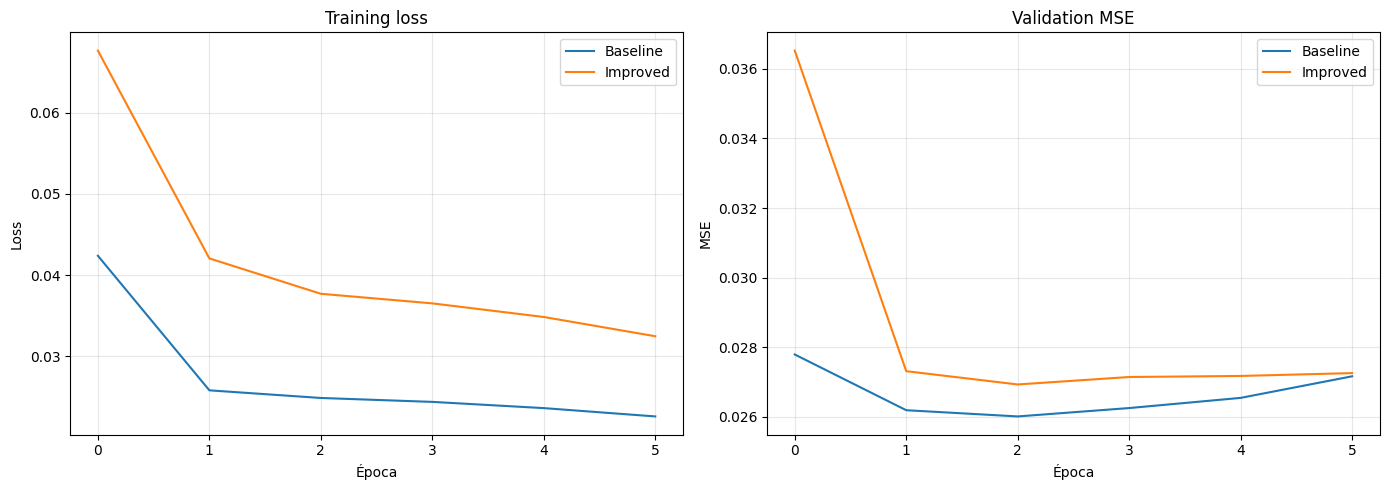

Gráfica guardada en: /content/drive/MyDrive/MLSM/Lab 3/results_v2/training_curves_v2.png


In [17]:
# Curvas de entrenamiento y validación.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(baseline_history["train_loss"], label="Baseline")
axes[0].plot(improved_history["train_loss"], label="Improved")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(baseline_history["val_mse"], label="Baseline")
axes[1].plot(improved_history["val_mse"], label="Improved")
axes[1].set_title("Validation MSE")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves_v2.png", dpi=200, bbox_inches="tight")
plt.show()
print("Gráfica guardada en:", RESULTS_DIR / "training_curves_v2.png")

## 15. Escucha y visualización de reconstrucciones

Por último, reconstruimos un ejemplo del conjunto de validación que no se ha utilizado para actualizar los pesos.

Mostramos:
- Audio original.
- Reconstrucción del baseline.
- Reconstrucción del modelo mejorado.

También calculamos el MSE de este ejemplo concreto. Este valor no debe confundirse con el MSE medio de todo el conjunto de validación.

In [18]:
# Elegimos un ejemplo fijo del conjunto de validación.
example = val_dataset[0].unsqueeze(0).to(DEVICE)

baseline_model.eval()
improved_model.eval()

with torch.no_grad():
    baseline_reconstruction = baseline_model(example)
    improved_reconstruction = improved_model(example)

original_audio = example.squeeze(0).cpu().numpy()
baseline_audio = baseline_reconstruction.squeeze(0).cpu().numpy()
improved_audio = improved_reconstruction.squeeze(0).cpu().numpy()

baseline_example_mse = np.mean((original_audio - baseline_audio) ** 2)
improved_example_mse = np.mean((original_audio - improved_audio) ** 2)

print(f"MSE del ejemplo - Baseline: {baseline_example_mse:.6f}")
print(f"MSE del ejemplo - Improved: {improved_example_mse:.6f}")

print("Audio original:")
display(Audio(original_audio, rate=SAMPLE_RATE))

print("Reconstrucción baseline:")
display(Audio(np.clip(baseline_audio, -1, 1), rate=SAMPLE_RATE))

print("Reconstrucción mejorada:")
display(Audio(np.clip(improved_audio, -1, 1), rate=SAMPLE_RATE))
# Guardamos el audio original y las dos reconstrucciones como archivos WAV.
import soundfile as sf
sf.write(RESULTS_DIR / "validation_original_v2.wav", original_audio, SAMPLE_RATE)
sf.write(RESULTS_DIR / "validation_baseline_reconstruction_v2.wav", baseline_audio, SAMPLE_RATE)
sf.write(RESULTS_DIR / "validation_improved_reconstruction_v2.wav", improved_audio, SAMPLE_RATE)
print("Audios WAV guardados en:", RESULTS_DIR)


MSE del ejemplo - Baseline: 0.019812
MSE del ejemplo - Improved: 0.020619
Audio original:


Reconstrucción baseline:


Reconstrucción mejorada:


Audios WAV guardados en: /content/drive/MyDrive/MLSM/Lab 3/results_v2


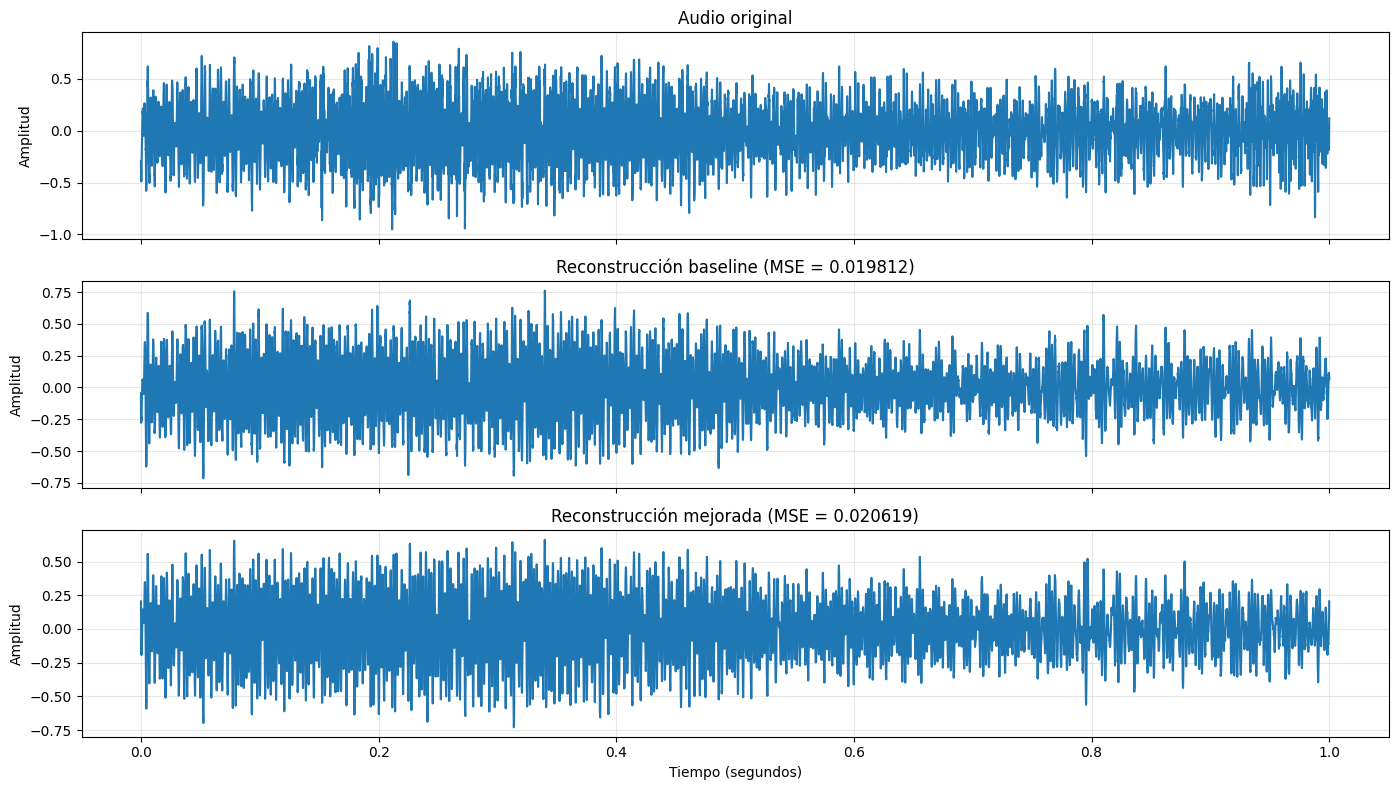

Gráfica guardada en: /content/drive/MyDrive/MLSM/Lab 3/results_v2/audio_reconstruction_comparison_v2.png


In [19]:
# Representamos las tres señales en el dominio temporal.
time_axis = np.arange(INPUT_LENGTH) / SAMPLE_RATE

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(time_axis, original_audio)
axes[0].set_title("Audio original")

axes[1].plot(time_axis, baseline_audio)
axes[1].set_title(f"Reconstrucción baseline (MSE = {baseline_example_mse:.6f})")

axes[2].plot(time_axis, improved_audio)
axes[2].set_title(f"Reconstrucción mejorada (MSE = {improved_example_mse:.6f})")

axes[2].set_xlabel("Tiempo (segundos)")

for ax in axes:
    ax.set_ylabel("Amplitud")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "audio_reconstruction_comparison_v2.png", dpi=200, bbox_inches="tight")
plt.show()
print("Gráfica guardada en:", RESULTS_DIR / "audio_reconstruction_comparison_v2.png")

## 16. Conclusiones

Completa esta sección después de ejecutar el notebook. Utiliza los valores que se han calculado en las celdas anteriores.

En el informe final conviene responder:

1. ¿Qué modelo obtiene menor MSE de validación?
2. ¿En qué época consigue cada modelo su mejor resultado?
3. ¿Cuánto mejora o empeora el modelo mejorado respecto al baseline?
4. ¿La escucha y las gráficas son coherentes con los valores de MSE?
5. ¿Qué limitaciones tiene este experimento?

### Consideraciones sobre reproducibilidad

- La partición entrenamiento/validación utiliza una semilla fija.
- Las inicializaciones de los modelos utilizan la misma semilla.
- Los DataLoaders se recrean con el mismo generador, por lo que utilizan el mismo orden de ejemplos.
- Los recortes de entrenamiento dependen del índice del archivo y de la época. Ambos modelos reciben así los mismos segmentos.
- La validación siempre utiliza el segmento central de cada audio.
- Se utiliza `num_workers=0` para evitar problemas asociados a procesos secundarios.

Aun así, la reproducibilidad exacta puede depender de la versión de PyTorch, CUDA, GPU y de las operaciones disponibles. Las semillas reducen la variabilidad, pero no garantizan necesariamente resultados idénticos en cualquier hardware.

### Limitaciones

Este experimento reconstruye segmentos de un segundo, no canciones completas. Además, el MSE mide diferencias entre muestras y no representa por sí solo toda la calidad perceptual del audio. La pérdida espectral intenta complementar esa medida, pero la comparación solicitada se basa en validation MSE.

In [20]:
# Generamos un resumen con los resultados reales de esta ejecución.
report_text = f"""# Lab 3 — Informe de resultados (versión 2)

## Resultados

| Modelo | Mejor época | Mejor validation MSE |
|---|---:|---:|
| Baseline | {baseline_best_epoch} | {baseline_best_mse:.8f} |
| Improved | {improved_best_epoch} | {improved_best_mse:.8f} |

Mejora relativa del MSE del modelo mejorado respecto al baseline: {relative_improvement:.2f}%.

## Configuración

- Frecuencia de muestreo: {SAMPLE_RATE} Hz
- Longitud de entrada: {INPUT_LENGTH} muestras
- Bottleneck: {BOTTLENECK_SIZE} valores
- Tasa de compresión nominal: {COMPRESSION_RATE:.2f}:1
- Semilla: {SEED}

## Interpretación automática

{'El modelo mejorado obtiene un menor MSE de validación.' if improved_best_mse < baseline_best_mse else 'El baseline obtiene un menor MSE de validación.' if improved_best_mse > baseline_best_mse else 'Ambos modelos obtienen el mismo MSE de validación.'}

Los resultados corresponden a esta ejecución del notebook y no deben sustituirse por valores de ejecuciones anteriores.
"""

report_path = RESULTS_DIR / "experimental_report_v2.md"
report_path.write_text(report_text, encoding="utf-8")
print(report_text)
print("Informe guardado en:", report_path)
print("\nTodos los resultados de esta versión están en:", RESULTS_DIR)

# Lab 3 — Informe de resultados (versión 2)

## Resultados

| Modelo | Mejor época | Mejor validation MSE |
|---|---:|---:|
| Baseline | 3 | 0.02601200 |
| Improved | 3 | 0.02693072 |

Mejora relativa del MSE del modelo mejorado respecto al baseline: -3.53%.

## Configuración

- Frecuencia de muestreo: 16000 Hz
- Longitud de entrada: 16000 muestras
- Bottleneck: 512 valores
- Tasa de compresión nominal: 31.25:1
- Semilla: 42

## Interpretación automática

El baseline obtiene un menor MSE de validación.

Los resultados corresponden a esta ejecución del notebook y no deben sustituirse por valores de ejecuciones anteriores.

Informe guardado en: /content/drive/MyDrive/MLSM/Lab 3/results_v2/experimental_report_v2.md

Todos los resultados de esta versión están en: /content/drive/MyDrive/MLSM/Lab 3/results_v2
